## 1. Data Exploration (EDA)

In [1]:
from pathlib import Path
base_dir=Path("/kaggle/input/competitions/recodai-luc-scientific-image-forgery-detection")
print("Top level contents",[p.name for p in base_dir.iterdir()])

Top level contents ['sample_submission.csv', 'train_images', 'supplemental_masks', 'train_masks', 'supplemental_images', 'test_images']


In [2]:
auth_dir=Path("/kaggle/input/competitions/recodai-luc-scientific-image-forgery-detection/train_images/authentic")
forged_dir=Path("/kaggle/input/competitions/recodai-luc-scientific-image-forgery-detection/train_images/forged")
mask_dir=Path("/kaggle/input/competitions/recodai-luc-scientific-image-forgery-detection/train_masks")

In [3]:
auth_files=sorted(auth_dir.glob("*"))
forged_files=sorted(forged_dir.glob("*"))
masked_files=sorted(mask_dir.glob("*.npy"))
print(f"Authentic images:{len(auth_files)}")
print(f"Forged images:{len(forged_files)}")
print(f"Masked files(.npy):{len(masked_files)}")
print(f"Sample forged image: {forged_files[4].name}")
print(f"Sample masked image: {masked_files[4].name}")

Authentic images:2377
Forged images:2751
Masked files(.npy):2751
Sample forged image: 10070.png
Sample masked image: 10070.npy


Image shape: (712, 414, 3)
Mask Shape (2, 712, 414)
Mask dtype uint8
Unique mask value [0 1]


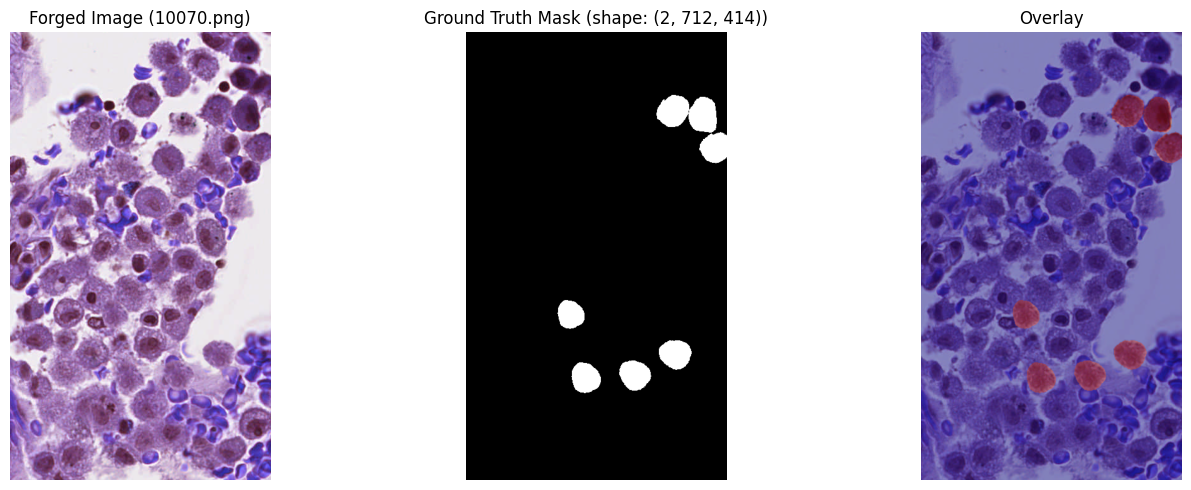

In [4]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
img_path=forged_files[4]
mask_path=mask_dir/f"{img_path.stem}.npy"
img=np.array(Image.open(img_path).convert("RGB"))
mask=np.load(mask_path)
print("Image shape:",img.shape)
print("Mask Shape",mask.shape)
print("Mask dtype",mask.dtype)
print("Unique mask value",np.unique(mask))

mask_2d=mask.max(axis=0) if mask.ndim==3 else mask
fig,axes =plt.subplots(1,3,figsize=(15,5))

axes[0].imshow(img)
axes[0].set_title(f"Forged Image ({img_path.name})")
axes[0].axis("off")

axes[1].imshow(mask_2d,cmap="gray")
axes[1].set_title(f"Ground Truth Mask (shape: {mask.shape})")
axes[1].axis("off")

axes[2].imshow(img) 
axes[2].imshow(mask_2d>0,cmap="jet",alpha=0.45)
axes[2].set_title("Overlay")
axes[2].axis("off")
plt.tight_layout()
plt.show()


In [5]:
import pandas as pd
records=[]
for img_path in auth_files:
    with Image.open(img_path) as im:
        w,h=im.size
        records.append({
            "case_id":img_path.stem,
            "image_path":str(img_path),
            "mask_path":"",
            "label":0,
            "width":w,
            "height":h,
            "n_regions":0,
            "forged_ratio":0.0
        })
for img_path in forged_files:
    with Image.open(img_path) as im:
        w,h=im.size
    m_path=mask_dir/f"{img_path.stem}.npy"
    mask=np.load(m_path)

    n_regions=mask.shape[0] if mask.ndim==3 else 1
    mask_2d=mask.max(axis=0) if mask.ndim==3 else mask
    forged_ratio=float((mask_2d>0).mean())
    records.append({
        "case_id":img_path.stem,
        "image_path":str(img_path),
        "mask_path":str(m_path),
        "label":1,
        "width":w,
        "height":h,
        "n_regions":n_regions,
        "forged_ratio":forged_ratio
    })
df=pd.DataFrame(records)

print(f"Total images indexed: {len(df)}")
print("\n Top 5 Most common Image sizes (Width x Height)")
print(df.groupby(["width","height"]).size().sort_values(ascending=False).head(5))

print("\n Number of forged regions per forged image")
print(df[df["label"]==1]["n_regions"].value_counts().sort_index())

print("\n Forged pixel area% of forged image")
print((df[df["label"]==1]["forged_ratio"]*100).describe().round(2))
print(df.isnull().sum())

Total images indexed: 5128

 Top 5 Most common Image sizes (Width x Height)
width  height
1000   666       686
256    256       605
1600   1200      530
696    520       256
320    256       229
dtype: int64

 Number of forged regions per forged image
n_regions
1    1869
2     701
3     174
4       5
5       2
Name: count, dtype: int64

 Forged pixel area% of forged image
count    2751.00
mean        5.52
std         6.92
min         0.04
25%         0.75
50%         2.71
75%         8.09
max        52.27
Name: forged_ratio, dtype: float64
case_id         0
image_path      0
mask_path       0
label           0
width           0
height          0
n_regions       0
forged_ratio    0
dtype: int64


## 2. Dataset Splitting

In [6]:
from sklearn.model_selection import StratifiedGroupKFold

def get_visual_hash(img_path):
    with Image.open(img_path) as im:
        small=im.convert("L").resize((8,8))
        pixels=np.asarray(small,dtype=np.float32)
        bits=(pixels>pixels.mean()).flatten()
        return "".join("1" if b else "0" for b in bits)
df["visual_hash"]=[get_visual_hash(p) for p in df["image_path"]]
dus_groups=df.groupby("visual_hash").filter(lambda g: len(g)>1)
print(f"Near duplication visual groups found: {dus_groups["visual_hash"].nunique()} ({len(dus_groups)} images)")

df["size_bin"]=pd.qcut(df["forged_ratio"],q=4,labels=False,duplicates="drop")
df["strat_key"]=df["label"].astype(str)+"_"+df["size_bin"].astype(str)

sgkf=StratifiedGroupKFold(n_splits=6,shuffle=True,random_state=42)
df["fold"]= -1
for fold_num, (_,val_idx) in enumerate(sgkf.split(df,df["strat_key"],groups=df["visual_hash"])):
    df.loc[val_idx,"fold"]=fold_num
fold_to_split={0:"test",1:"val",2:"train",3:"train",4:"train",5:"train"}
df["split"]=df["fold"].map(fold_to_split)
df.drop(columns=["size_bin","strat_key","fold"]).to_csv("/kaggle/working/dataset_split.csv", index=False)
print("Final Split Breakdown (0 = Authentic, 1 = Forged)")
print(pd.crosstab(df["split"],df["label"],margins=True))

Near duplication visual groups found: 582 (1278 images)
Final Split Breakdown (0 = Authentic, 1 = Forged)
label     0     1   All
split                  
test    394   459   853
train  1592  1839  3431
val     391   453   844
All    2377  2751  5128


## 3. Evaluation Metrics

In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,roc_auc_score
def compute_pixel_metrics(pred_mask,true_mask):
    pred=(pred_mask>0).astype(np.float32)
    true=(true_mask>0).astype(np.float32)
    if true.sum()==0:
        score=1.0 if pred.sum()==0 else 0.0
        return score,score
    intersection=(pred*true).sum()
    dice=(2.0*intersection)/(pred.sum() + true.sum()+1e-7)
    union=pred.sum()+true.sum()-intersection
    iou=intersection/(union+1e-7)
    return float(dice),float(iou)

def compute_image_met(y_true,y_prob,threshold=0.5):
    y_pred=(np.array(y_prob)>=threshold).astype(int)
    return {
        "Accuracy":round(accuracy_score(y_true,y_pred),4),
        "Precision":round(precision_score(y_true,y_pred,zero_division=0),4),
        "Recall":round(recall_score(y_true,y_pred,zero_division=0),4),
        "F1":round(f1_score(y_true,y_pred,zero_division=0),4),
        "ROC_AUC":round(roc_auc_score(y_true,y_prob),4)
    }
true_forged=np.array([[0,0,0,0],
                      [0,1,1,0],
                      [0,1,1,0],
                      [0,0,0,0]])
pred_perfect=true_forged.copy()
pred_half=np.array([[0,0,0,0],
                   [0,1,0,0],
                   [0,1,0,0],
                   [0,0,0,0]])
pred_empty=np.zeros((4,4))
print("1. Perfect match on forged image :", compute_pixel_metrics(pred_perfect, true_forged))
print("2. Half overlap on forged image  :", compute_pixel_metrics(pred_half, true_forged))
print("3. Missed forgery (all zeros)    :", compute_pixel_metrics(pred_empty, true_forged))
print("4. Authentic image, correct empty:", compute_pixel_metrics(pred_empty, pred_empty))
print("5. Authentic image, false alarm  :", compute_pixel_metrics(pred_half, pred_empty))

1. Perfect match on forged image : (1.0, 1.0)
2. Half overlap on forged image  : (0.6666666865348816, 0.5)
3. Missed forgery (all zeros)    : (0.0, 0.0)
4. Authentic image, correct empty: (1.0, 1.0)
5. Authentic image, false alarm  : (0.0, 0.0)


## 4. PyTorch Dataset & DataLoader